# 3 · Your own planet

**Covered topics:** how to describe a planet other than Jupiter — its mass, radius and rotation, how to hand PyToF a density profile directly instead of a barotrope, how atmospheres and density jumps are treated, and how to tune a model to measured gravitational moments.

Notebook 1 started from a barotrope $\rho(P)$ and let PyToF find densities and shape together (`relax_to_barotrope`). There are two more entry points, and the choice depends on what you know about the interior:

| you provide | method | PyToF computes |
|---|---|---|
| $\rho(P)$ | `set_barotrope(f)` + `relax_to_barotrope()` | pressures, densities, shape, and $J_{2n}$ |
| $\rho(l)$ on the grid | set `X.li`, `X.rhoi`, `X.m_rot_calc` + `relax_to_shape()` | shape and $J_{2n}$ |
| $\rho(l)$ on the grid, possibly with an atmosphere | `relax_to_density()` | pressures, shape, and $J_{2n}$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from scipy.optimize import brentq

from PyToF import ToF
from tutorial_utils import LABELS, profiles

plt.rcParams["figure.figsize"] = (5.2, 3.9)  # smaller default figures

## The physical parameters

| option | meaning | default (Jupiter) |
|---|---|---|
| `M_phys` | mass [kg] | $1.898\times10^{27}$ |
| `R_phys` | `[value in m, kind]` with kind `'equatorial'`, `'mean'` or `'polar'` | `[71492000, 'equatorial']` |
| `R_ref` | reference radius in the definition of the $J_{2n}$ [m] | the value in `R_phys` |
| `Period` | rotation period [s] | 9.925 h |
| `P0` | pressure at the outer surface [Pa] | 0 |
| `G` | gravitational constant [m³ kg⁻¹ s⁻²] | $6.67385\times10^{-11}$ |

`R_phys` tells PyToF which radius your outermost level surface corresponds to. `R_ref` is purely a convention of the output: $J_{2n}$ is defined with respect to a reference radius, usually the equatorial radius at the 1 bar level. Changing it rescales the moments by $(R_\mathrm{ref,1}/R_\mathrm{ref,2})^{2n}$ and changes nothing physical. As an example, we now consider Neptune with the values of Wang et al. (2023, [doi:10.1051/0004-6361/202244537](https://doi.org/10.1051/0004-6361/202244537)), Lindal (1992, [doi:10.1086/116119](https://doi.org/10.1086/116119)) and Karkoschka (2011, [doi:10.1016/j.icarus.2011.05.013](https://doi.org/10.1016/j.icarus.2011.05.013)), with the gravitational constant of CODATA 2022 (Mohr et al. 2025, [doi:10.1103/RevModPhys.97.025002](https://doi.org/10.1103/RevModPhys.97.025002)):

In [2]:
neptune = dict(
    G=6.67430e-11,  # CODATA 2022
    M_phys=1.02409e26,  # Jacobson (2009)
    R_ref=25225e3,  # reference radius of the J's, Wang et al. (2023)
    R_phys=[24766e3, "equatorial"],  # radius at 1 bar, Lindal (1992)
    Period=57479,  # Karkoschka (2011)
    P0=1e5,  # 1 bar
)

## A density profile you provide

Suppose you have an interior model as density versus radius — from a table, a formula or another code. PyToF works on a grid of `N` mean radii $l$, **starting at the outer surface and decreasing**. Only the outermost one, $l_\mathrm{max}$, has to agree with the radius you give in `R_phys`. A uniform-density test planet would be implemented as shown by the code below.

> **Always set `X.li`, `X.rhoi` and `X.m_rot_calc`**: otherwise PyToF silently relaxes its default planet instead of yours. The rotation parameter $m = \omega^2 l_\mathrm{max}^3/(GM)$ has to be defined with the outermost mean radius $l_\mathrm{max}$ = `X.li[0]` (not the equatorial radius). `ToF(...)` only sets a default and `relax_to_shape()` never recomputes it. This is specific to `relax_to_shape()`: `relax_to_density()` and `relax_to_barotrope()` recompute `X.m_rot_calc` themselves, so a wrong value there has no effect (`relax_to_density()` needs `X.li` and `X.rhoi` to be set as well, `relax_to_barotrope()` does not need any of these three quantities, see Notebook 1).


In [3]:
N = 1024
radius = 1e6  # m
period = 24 * 3600  # s
radii = radius * np.linspace(1, 1e-3, N)  # outer surface first
densities = 1000 * np.ones(N)  # kg/m^3
mass = -4 * np.pi * trapezoid(densities * radii**2, radii)  # minus: radii decrease

X = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "mean"], Period=period)

X.li = radii  # li, rhoi and m_rot_calc always have to be set!
X.rhoi = densities
# rotational parameter m = omega^2 l_max^3 / (G M) with the outermost mean radius l_max = X.li[0]
X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass)

n_iterations = X.relax_to_shape()
X.get_Js_errors()
print("iterations:", n_iterations)
for n in range(1, 4):
    print(f"J_{2 * n} = {X.Js[n]:.5e} +/- {X.Js_errors[n]:.1e}")

iterations: 49
J_2 = 9.54772e-03 +/- 4.9e-08
J_4 = -1.95344e-04 +/- 4.9e-08
J_6 = 5.17427e-06 +/- 4.5e-08


`relax_to_shape()` does not touch your densities; it only finds the shape for them (iterating until the moments change by less than `dJ_tol`). It also checks that the shape is consistent with the radius you declared in `R_phys` and warns if not. The grid always consists of mean radii, and only the outermost one has to agree with `R_phys`: for `"mean"` the two are equal, for `"equatorial"` (or `"polar"`) PyToF compares your value with the equatorial (polar) radius of the outermost level surface. A typical mistake is to declare the outermost mean radius as an equatorial radius, which for a rotating planet is larger:

In [4]:
Y = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "equatorial"], Period=period)
Y.li, Y.rhoi, Y.m_rot_calc = radii, densities, X.m_rot_calc
Y.relax_to_shape();  # warns

/tmp/ipykernel_7584/2543654295.py:3: PyToFWarning: Your provided equatorial radius is not consistent with the shape of the planet calculated by PyToF! Your value: 1.00000e+06 / PyToF value: 1.00805e+06
  Y.relax_to_shape();  # warns


Density profiles are often given as a function with free parameters. A common pattern is to define the shape of the profile and normalize it to the mass, so that mass is conserved by construction:

J_2 = 4.10398e-03 +/- 2.1e-08


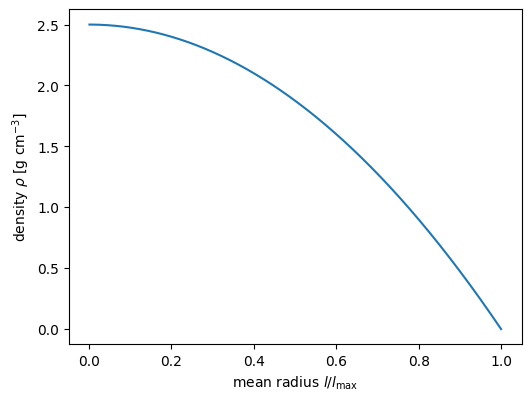

In [5]:
def dens_function(radii, mass, param=None):
    x = radii / np.max(radii)
    densities = 1 - x**2  # shape of the profile
    densities /= -4 * np.pi * trapezoid(densities * radii**2, radii) / mass  # renormalize
    return densities

X = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "mean"], Period=period)
X.li = radii
X.rhoi = dens_function(radii, mass)
X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass)
X.relax_to_shape()
X.get_Js_errors()
print("J_2 = {:.5e} +/- {:.1e}".format(X.Js[1], X.Js_errors[1]))

p = profiles(X)
fig, ax = plt.subplots(layout="constrained")
ax.plot(p["r"], p["rho"])
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"]);

## Density jumps

Real planets have composition boundaries, where density jumps. PyToF integrates with Simpson's rule by default, which is more accurate for smooth profiles but cannot handle a jump. When it detects the problem it **switches to the trapezoid rule on its own** and issues an `AccuracyWarning`; the result is then valid but somewhat less accurate (see notebook 5). `X.simpson_in_use` says which rule was used. A planet with a dense core (3000 kg/m³) inside half of its radius:

In [6]:
dens_core = np.where(radii < 0.5 * radius, 3000.0, 1000.0)
mass_core = -4 * np.pi * trapezoid(dens_core * radii**2, radii)

X = ToF(N=N, order=4, M_phys=mass_core, R_phys=[radius, "mean"], Period=period, R_ref=radius)
X.li, X.rhoi = radii, dens_core
X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass_core)
X.relax_to_shape()
print("Simpson's rule in use:", X.simpson_in_use)

Simpson's rule in use: False


/home/lumo/Code/PyToF_dev/PyToF/AlgoToF.py:539: AccuracyWarning: Reverting to the more stable and less accurate trapezoid rule for integration because S_0, itself proportional to the enclosed mass function, has become non-monotonic. Discontinuities in the density gradient due to jumps in density are likely responsible.
  warn_simpson_fallback(


The fallback is reset by `X.reset()`, so a new calculation on the same object starts with Simpson's rule again. If you know that your profile has jumps, `use_simpson=False` skips the attempt.

## An atmosphere

The outermost part of a planet is often not described well by the interior model, for example because the interior is a barotrope or a density profile that does not hold at low pressures. PyToF can therefore join the interior to a separate atmosphere model:

* The atmosphere model is any function `atmosphere(l, P)` that returns densities [kg/m³] for the mean radii `l` [m] and the pressures `P` [Pa] of the level surfaces it is applied to. It may use either argument, both, or only one of them.
* `atmosphere_until` is the pressure [Pa] up to which it is used: all level surfaces with a lower pressure get the atmosphere densities, all others keep the interior ones. Switch it on with `use_atmosphere=True`.
* The pressures are only known once the shape is found, so the level surface where the transition sits is updated during the iterations (it can only move inwards). It is reported with `verbosity=2`.
* PyToF does not smooth the transition: if the two models do not agree at `atmosphere_until`, the result has a density jump, which is treated like any other (see above).

Here we use `relax_to_density()`, and in contrast to `relax_to_shape()` above we do not set `X.m_rot_calc`: this method recomputes the rotation parameter from `Period`, `M_phys` and the outermost mean radius `X.li[0]` in every iteration, and it also rescales the radii to `R_phys` and the densities to `M_phys`, so only the grid `X.li` and the densities `X.rhoi` are input.


Simpson's rule in use: False


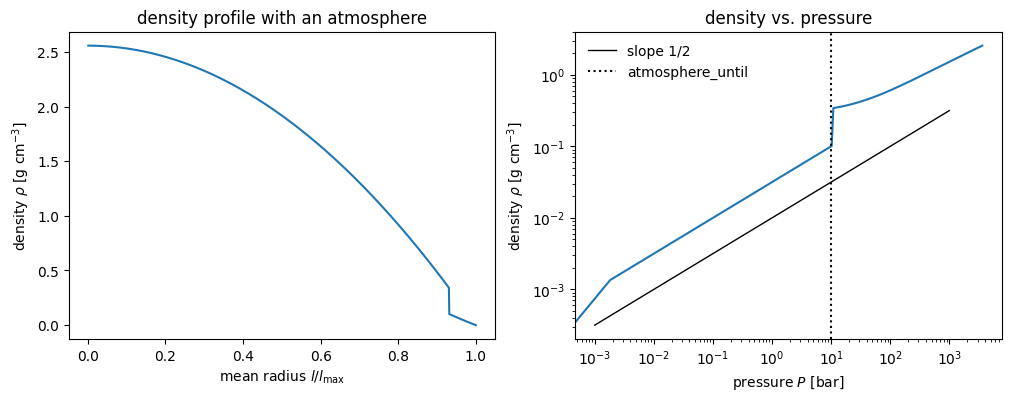

In [17]:
def atmosphere(norm_radii, pressure, K=1e2):
    return (pressure / K) ** (1 / 2)

atm = dict(use_atmosphere=True, atmosphere=atmosphere, atmosphere_until=1e6)  # 10 bar

X = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "mean"], Period=period, **atm)
X.li, X.rhoi = radii, dens_function(radii, mass)  # no m_rot_calc needed, relax_to_density() recomputes it

X.relax_to_density()  # densities are given, PyToF finds the shape and the pressures
print("Simpson's rule in use:", X.simpson_in_use)
p = profiles(X)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.9), layout="constrained")

axs[0].plot(p["r"], p["rho"])
axs[0].set_xlabel(LABELS["r"])
axs[0].set_ylabel(LABELS["rho"])
axs[0].set_title("density profile with an atmosphere")

# log-log: the atmosphere (rho ~ P^(1/2)) is a straight line with slope 1/2,
# the interior has a different slope; the outermost point has P = 0
axs[1].plot(p["P"][:-1], p["rho"][:-1])
axs[1].set_xscale("log")
axs[1].set_yscale("log")
P_line = np.array([1e-3, 1e3])  # bar
axs[1].plot(P_line, P_line ** 0.5/100, "k", lw=1, label="slope 1/2")
axs[1].axvline(1e6 / 1e5, color="k", linestyle=":", label="atmosphere_until")
axs[1].set_xlabel(LABELS["P"])
axs[1].set_ylabel(LABELS["rho"])
axs[1].set_title("density vs. pressure")
axs[1].legend(frameon=False);

At 10 bar the density jumps from the atmosphere model to the interior profile — a density jump, so PyToF uses the trapezoid rule here. The same works with a barotrope instead of a given density profile: set `use_atmosphere`, `atmosphere`, `atmosphere_until` and call `relax_to_barotrope()`.

## Tuning a model to measured moments: a two-layer Neptune

A typical use is to adjust a few parameters until the gravitational moments match the measured ones. Consider Neptune with $J_2 = (3401.655 \pm 1.850)\times10^{-6}$ and $J_4 = (-33.294 \pm 10.000)\times10^{-6}$ (Wang et al. 2023, [doi:10.1051/0004-6361/202244537](https://doi.org/10.1051/0004-6361/202244537); the paper argues that a more realistic uncertainty of $J_2$ is $\pm3.994\times10^{-6}$, which we use below).

A minimal interior model is a two-layer polytrope: $\rho = \sqrt{P/K}$ everywhere, but with the density multiplied by `ratio` above a pressure `P_core` (a fraction of the central pressure), so the core has $K_\mathrm{core} = K/\mathrm{ratio}^2$. The densities are rescaled to the mass, so an overall $K$ cancels and we can set $K = 1$; what matters is the ratio of the two $K$, which is the one free parameter `ratio` here. (A barotrope receives the pressure array and the parameter list set in `baro_param`.)

In [8]:
def barotrope(P, param):
    P_core, ratio = param
    rho = np.sqrt(P)  # K = 1: only the ratio of the K of the two layers matters
    return np.where(P / np.max(P) > P_core, ratio * rho, rho)

def neptune_model(ratio, P_core=0.01, order=7, N=512):
    X = ToF(**neptune, N=N, order=order, baro_param=[P_core, ratio])
    X.set_barotrope(barotrope)
    X.relax_to_barotrope()
    return X

for ratio in (1.0, 1.25, 1.5, 2.0):
    X = neptune_model(ratio)
    print(f"ratio = {ratio:4.2f}:  J2 = {X.Js[1] * 1e6:7.1f}e-6   J4 = {X.Js[2] * 1e6:6.2f}e-6   I/(M R^2) = {X.get_NMoI():.4f}")

ratio = 1.00:  J2 =  4312.2e-6   J4 = -50.31e-6   I/(M R^2) = 0.2643


ratio = 1.25:  J2 =  3829.7e-6   J4 = -40.13e-6   I/(M R^2) = 0.2516


ratio = 1.50:  J2 =  3403.1e-6   J4 = -32.11e-6   I/(M R^2) = 0.2397


ratio = 2.00:  J2 =  2668.6e-6   J4 = -20.51e-6   I/(M R^2) = 0.2167


$J_2$ falls monotonically with the core density, and the measured value lies between the models above, so a root finder can tune `ratio` to it. We use `scipy.optimize.brentq` to find the `ratio` for which $J_2(\mathrm{ratio}) - J_{2,\mathrm{measured}} = 0$. It needs an interval `[a, b]` in which the function changes sign (here `ratio` between 1 and 2, which the table above confirms), needs no derivatives, and is guaranteed to converge: it combines bisection, which is slow but safe, with faster interpolation steps. Every function evaluation is one full PyToF model (a fraction of a second), and `xtol` is the accuracy of `ratio`, chosen far below what the data can constrain. Since PyToF itself has a numerical error, `get_Js_errors()` tells how it compares to the measurement uncertainty:

ratio = 1.5013 (8 models)


J2 = 3401.655e-6 +/- 0.25e-6 (PyToF), measured 3401.655e-6 +/- 3.994e-6
J4 = -32.08e-6 +/- 0.005e-6 (PyToF), measured -33.29e-6 +/- 10.00e-6


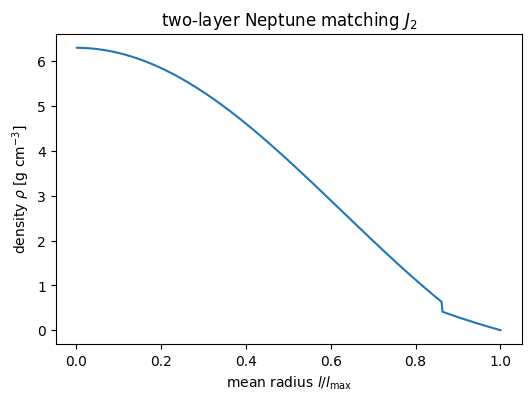

In [9]:
J2_measured, J2_sigma = 3401.655e-6, 3.994e-6
J4_measured, J4_sigma = -33.294e-6, 10.0e-6

ratio_fit, root = brentq(lambda ratio: neptune_model(ratio).Js[1] - J2_measured, 1.0, 2.0, xtol=1e-6, full_output=True)
print(f"ratio = {ratio_fit:.4f} ({root.function_calls} models)")

X = neptune_model(ratio_fit)
X.get_Js_errors()
print(f"J2 = {X.Js[1] * 1e6:.3f}e-6 +/- {X.Js_errors[1] * 1e6:.2f}e-6 (PyToF), measured {J2_measured * 1e6:.3f}e-6 +/- {J2_sigma * 1e6:.3f}e-6")
print(f"J4 = {X.Js[2] * 1e6:.2f}e-6 +/- {X.Js_errors[2] * 1e6:.3f}e-6 (PyToF), measured {J4_measured * 1e6:.2f}e-6 +/- {J4_sigma * 1e6:.2f}e-6")

p = profiles(X)
fig, ax = plt.subplots(layout="constrained")
ax.plot(p["r"], p["rho"])
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])
ax.set_title("two-layer Neptune matching $J_2$");

$J_2$ matches by construction. The numerical error of PyToF at this resolution is about 6% of the measurement uncertainty of $J_2$ (and far below it for $J_4$): small, but not something to ignore for a precise fit; a larger `N` reduces it (see notebook 5). $J_4$ was not used: it is a prediction of the model, and it comes out within its measurement uncertainty. With more free parameters than data and uncertainties on the data, a one-dimensional root search is no longer enough: one needs to explore which parameter combinations are consistent with the data within their errors.

## Takeaways

* Give PyToF mass, radius (`R_phys`), rotation (`Period`) and, if you like, a reference radius for the moments (`R_ref`).
* Three entry points: barotrope → `relax_to_barotrope()`; density profile → set `X.li`, `X.rhoi`, `X.m_rot_calc` → `relax_to_shape()`; density profile with an atmosphere or pressures wanted → `relax_to_density()`.
* Grids run from the outer surface inward. Density jumps are fine: PyToF falls back to the trapezoid rule by itself.
* A PyToF model is cheap enough to sit inside a root finder or an optimizer.

Next: [4 · beyond the Js](04_beyond_the_Js.ipynb).